<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/lab-008-analysing-networks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 008 — Analysing a neural network

This notebook is about **looking at** a network: what can be measured about it before, during
and after training, and what these measurements tell us. All quantities are computed with a few lines of PyTorch and plotted with Matplotlib.

We start with the architecture alone (Section 1): a drawing, a table of the layers, the number of parameters and how it grows with width and depth,
trainable and frozen parameters, memory and computational cost, and finally the same information obtained with the ready-made tools `torchinfo` and
`torchview`. Section 2 examines the network before training, layer by layer: its weights, its activations and how many of its nodes are saturated, and the
gradients that the first optimisation step would use, together with the role of the initialisation scale. Section 3 follows the network during training,
through the losses on the training and validation sets and through the gradients and weight changes of every layer. These curves show when the network
begins to overfit, and Section 4 uses the validation set to choose the epoch at which training should have stopped. The chosen model is evaluated once on
the test set in Section 5, and Section 6 collects all characteristics of a model in one table. A summary (Section 7) and exercises with solutions
(Section 8) close the notebook.

Methods for interpreting *what* a network has learned (e.g. class activation maps for images) need convolutional networks and are discussed in later classes.

> To run this notebook in Google Colab, proceed as follows.
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages `numpy`, `matplotlib`, `torch`, `torchvision` and `pandas` are pre-installed in Colab; `torchinfo` and `torchview` are installed in Section 1.7 with `%pip`.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


Two functions from the previous notebook are needed throughout: `make_mlp` builds a dense network from a list of layer sizes, and `draw_network` draws it.

In [2]:
def make_mlp(layer_sizes, activation=nn.Tanh):
    """Dense network with the given layer sizes; `activation` after every hidden layer, none after the output layer."""
    layers = []
    for i in range(len(layer_sizes) - 1):
        layers.append(nn.Linear(layer_sizes[i], layer_sizes[i + 1]))
        if i < len(layer_sizes) - 2:
            layers.append(activation())
    return nn.Sequential(*layers)

The drawing function is the same as in the previous notebook. `linear_sizes` reads the layer sizes from the `nn.Linear` layers of a model,
so that every drawing shows the network that was built, and `dense_parameter_count` gives the number of parameters for these sizes.

In [3]:
def draw_network(layer_sizes, activations=None, title="", max_nodes=10, ax=None,
                 input_labels=None, output_labels=None):
    """
    Draw a fully connected network.
    layer_sizes : e.g. [1, 8, 1] = 1 input, one hidden layer with 8 nodes, 1 output
    activations : names of the activation functions of the hidden layers, e.g. ["tanh"]
    max_nodes   : larger layers are drawn with max_nodes nodes and a vertical "..." in the middle
    input_labels, output_labels : optional texts written next to the input and output nodes, e.g. ["$x$"]
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(1.9 * len(layer_sizes) + 1, 4.2))
    n_layers = len(layer_sizes)
    positions = []                                   # list of (x, y) arrays, one per layer
    for i, n in enumerate(layer_sizes):
        shown = min(n, max_nodes)
        y = np.linspace(-1, 1, shown) if shown > 1 else np.array([0.0])
        positions.append((np.full(shown, float(i)), y * min(1.0, shown / max_nodes + 0.15)))
    # connections between neighbouring layers
    for i in range(n_layers - 1):
        (x0, y0), (x1, y1) = positions[i], positions[i + 1]
        for a in y0:
            for b in y1:
                ax.plot([x0[0], x1[0]], [a, b], color="0.7", lw=0.6, zorder=1)
    # nodes and labels
    for i, (n, (xs, ys)) in enumerate(zip(layer_sizes, positions)):
        if i == 0:
            color, name = "C2", "input"
        elif i == n_layers - 1:
            color, name = "C3", "output"
        else:
            act = activations[i - 1] if activations is not None else ""
            color, name = "C0", f"hidden {i}" + (f"\n{act}" if act else "")
        ax.scatter(xs, ys, s=260, color=color, edgecolor="k", zorder=3)
        if n > max_nodes:                            # mark omitted nodes
            ax.text(xs[0] + 0.2, 0.0, "...", rotation=90, fontsize=14, va="center", ha="center",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=4)
        ax.text(xs[0], -1.35, f"{name}\n{n} node" + ("s" if n > 1 else ""), ha="center", va="top", fontsize=10)
    if input_labels is not None:
        for y, lab in zip(positions[0][1], input_labels):
            ax.text(-0.18, y, lab, ha="right", va="center", fontsize=12)
    if output_labels is not None:
        for y, lab in zip(positions[-1][1], output_labels):
            ax.text(n_layers - 1 + 0.18, y, lab, ha="left", va="center", fontsize=12)
    n_params = sum(n_in * n_out + n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))
    ax.set_title((title + "\n" if title else "") + f"layer sizes {layer_sizes},  {n_params} parameters", fontsize=11)
    ax.set_xlim(-0.8, n_layers - 0.2); ax.set_ylim(-2.1, 1.3)
    ax.axis("off")
    return ax

def linear_sizes(model):
    """Layer sizes [n_0, n_1, ..., n_L] of a dense network, read from its nn.Linear layers in the order of definition."""
    linear = [m for m in model.modules() if isinstance(m, nn.Linear)]
    return [linear[0].in_features] + [m.out_features for m in linear]

def dense_parameter_count(sizes):
    """Number of weights and biases of a dense network with these layer sizes."""
    return sum(n_out * (n_in + 1) for n_in, n_out in zip(sizes[:-1], sizes[1:]))

<hr/>
## 1. The architecture

### 1.1 Drawing of the network
The network analysed in this notebook has layer sizes $[1, 64, 64, 64, 1]$ with $\tanh$ activations: one input, three hidden layers of 64 nodes, one output.

It is deliberately much larger than the 30 training points of Section 2 require (8513 parameters, counted in Section 1.3), so that it is
able to overfit them (Section 4). Three hidden layers make the effects of depth on activations and gradients visible. $\tanh$ is used because for it
"saturated" has a simple meaning (Section 2.3). The width 64 itself is arbitrary: with widths 32 and 128 the same training run also shows a minimum of the
validation loss followed by a rise.

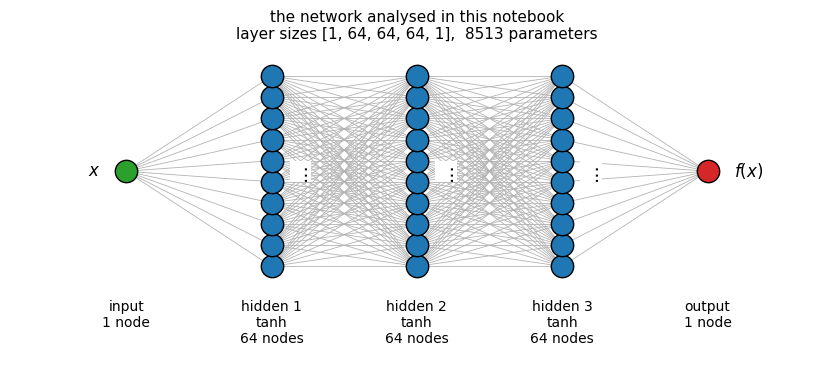

Sequential(
  (0): Linear(in_features=1, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=1, bias=True)
)


In [4]:
layer_sizes = [1, 64, 64, 64, 1]
torch.manual_seed(0)                 # fixes the random initial weights; Section 3 uses the same seed, so it trains exactly this network
model = make_mlp(layer_sizes)
assert linear_sizes(model) == layer_sizes
draw_network(linear_sizes(model), activations=["tanh"] * 3, title="the network analysed in this notebook",
             input_labels=["$x$"], output_labels=["$f(x)$"])
plt.show()
print(model)

### 1.2 A table of the layers
We pass a small batch through the layers one by one and record, for each layer, its type, the shapes of its input and output, the shapes of its parameters,
and the number of parameters. A `pandas.DataFrame` is a convenient container for such a table.

An `nn.Sequential` behaves like a list of layers: `for layer in model` runs over them in order, and `model[0]`, `model[-1]` select the first and the last
layer. In the table, `index` is the position of the module in the `Sequential`; it is not the layer index $l$ of Section 1.3. `type(layer).__name__` gives the name of the class of an object as a string (e.g. `'Linear'`), and `p.numel()` the number of entries of a tensor.

In [5]:
def layer_table(model, x):
    """One row per layer of an nn.Sequential model, for the input batch x."""
    rows = []
    for i, layer in enumerate(model):
        x_in = x
        x = layer(x)                                            # pass the batch through this layer
        params = list(layer.parameters())
        rows.append({
            "index": i,
            "layer": type(layer).__name__,
            "input shape": tuple(x_in.shape),
            "output shape": tuple(x.shape),
            "parameter shapes": [tuple(p.shape) for p in params],
            "parameters": sum(p.numel() for p in params),
            "trainable": sum(p.numel() for p in params if p.requires_grad),
        })
    return pd.DataFrame(rows)

table = layer_table(model, torch.zeros(8, 1))                   # 8 dummy inputs; batch size and values are arbitrary, only the shape (B, 1) matters
table

,index,layer,input shape,output shape,parameter shapes,parameters,trainable
0,0,Linear,"(8, 1)","(8, 64)","[(64, 1), (64,)]",128,128
1,1,Tanh,"(8, 64)","(8, 64)",[],0,0
2,2,Linear,"(8, 64)","(8, 64)","[(64, 64), (64,)]",4160,4160
3,3,Tanh,"(8, 64)","(8, 64)",[],0,0
4,4,Linear,"(8, 64)","(8, 64)","[(64, 64), (64,)]",4160,4160
5,5,Tanh,"(8, 64)","(8, 64)",[],0,0
6,6,Linear,"(8, 64)","(8, 1)","[(1, 64), (1,)]",65,65


Each `Linear` layer from $n_{\rm in}$ to $n_{\rm out}$ nodes has a weight matrix of shape $(n_{\rm out}, n_{\rm in})$ and a bias of length $n_{\rm out}$;
activation layers have no parameters and keep the shape. The batch dimension (8) is carried through the table unchanged.

### 1.3 Counting parameters
The layers are numbered from 0 to $L$, with $n_0$ the number of inputs and $n_L$ the number of outputs; for $[1, 64, 64, 64, 1]$ the sizes $n_0$ and
$n_4$ are 1 and the hidden sizes $n_1, n_2, n_3$ are 64. The `Linear` layer from layer $l-1$ to layer $l$ has $n_l n_{l-1}$ weights and $n_l$ biases,
$$n_l n_{l-1} + n_l = n_l(n_{l-1}+1) \tag{1}$$
parameters. The total from the table is compared with
$$P = \sum_{l=1}^{L} n_l\,(n_{l-1}+1) \tag{2}$$
and with PyTorch's own count.

In [6]:
by_formula = sum(n_out * (n_in + 1) for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))
by_table = table["parameters"].sum()
by_pytorch = sum(p.numel() for p in model.parameters())
print(f"formula: {by_formula},  table: {by_table},  PyTorch: {by_pytorch}")
for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
    print(f"  Linear({n_in}, {n_out}): {n_out} x {n_in} weights + {n_out} biases = {n_out * (n_in + 1)}")

formula: 8513,  table: 8513,  PyTorch: 8513
  Linear(1, 64): 64 x 1 weights + 64 biases = 128
  Linear(64, 64): 64 x 64 weights + 64 biases = 4160
  Linear(64, 64): 64 x 64 weights + 64 biases = 4160
  Linear(64, 1): 1 x 64 weights + 1 biases = 65


### 1.4 Number of parameters against width and depth
For a network $[1, W, \dots, W, 1]$ with $D$ hidden layers of width $W$ the count is
$$P(W, D) = W(1+1) + (D-1)\,W(W+1) + (W+1) . \tag{3}$$
The three terms are the first layer ($W$ weights and $W$ biases), the $D-1$ layers
from width $W$ to width $W$ ($W^2$ weights and $W$ biases each) and the output layer ($W$ weights and one bias). The count is therefore linear in the depth $D$
and, for two or more hidden layers, quadratic in the width $W$. On the log-log axes below a power law $W^k$ is a straight line of slope $k$.

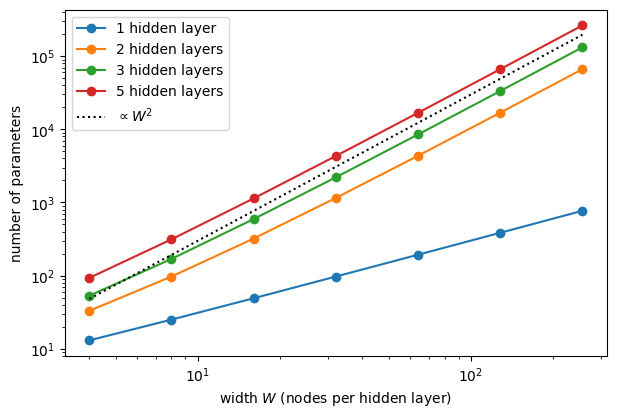

In [7]:
widths = np.array([4, 8, 16, 32, 64, 128, 256])
fig, ax = plt.subplots(figsize=(7, 4.5))
for depth in [1, 2, 3, 5]:
    counts = [sum(p.numel() for p in make_mlp([1] + [w] * depth + [1]).parameters()) for w in widths]
    ax.loglog(widths, counts, "o-", label=f"{depth} hidden layer" + ("s" if depth > 1 else ""))
ax.loglog(widths, 3 * widths**2, "k:", label=r"$\propto W^2$")    # only the slope 2 matters; the factor 3 places the line near the data
ax.set_xlabel("width $W$ (nodes per hidden layer)"); ax.set_ylabel("number of parameters"); ax.legend()
plt.show()

With one hidden layer the count grows only linearly ($3W+1$); every additional hidden layer adds a $W\times W$ matrix, so the deeper networks follow the $W^2$ line.

### 1.5 Trainable and frozen parameters
Setting `requires_grad = False` for a parameter **freezes** it: no gradient is computed for it, and an optimiser leaves it unchanged.
Freezing is used, for example, when a pretrained part of a network is kept fixed. Freezing the first layer of a copy of the model changes the count of trainable parameters as follows.

The copy must be made with `copy.deepcopy`. A plain assignment `frozen_model = model` only gives a second name to the same network, and a shallow
`copy.copy(model)` creates a new container that still holds the same parameter tensors: freezing it would freeze `model` as well.
`copy.deepcopy` duplicates every parameter.

In [8]:
frozen_model = copy.deepcopy(model)              # an independent copy, so that `model` itself stays unchanged
for p in frozen_model[0].parameters():           # module 0 of the `Sequential`, i.e. the first `Linear` layer
    p.requires_grad = False

trainable = sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in frozen_model.parameters())
print(f"total parameters: {total},  trainable: {trainable},  frozen: {total - trainable}  (= 64 weights + 64 biases of the first Linear layer)")

total parameters: 8513,  trainable: 8385,  frozen: 128  (= 64 weights + 64 biases of the first Linear layer)


### 1.6 Memory and computational cost
Every parameter is stored as a `float32` number of 4 bytes. One forward pass for one input needs, in every `Linear` layer, $n_{\rm in}\,n_{\rm out}$
multiplications and as many additions (a *multiply-add* per weight). These numbers set the scale for large networks: a model with $10^9$ parameters needs
4 GB only to store its weights.

The count of multiply-adds includes only the multiplications by weights; the bias additions and the activations add about $n_{\rm out}$ operations per layer,
which is small compared with $n_{\rm in}n_{\rm out}$ for wide layers. In the printout 1 kB is taken as 1024 bytes.

In [9]:
n_bytes = sum(p.numel() * p.element_size() for p in model.parameters())     # element_size() = bytes per number
mult_adds = sum(n_in * n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))
print(f"memory of the parameters: {n_bytes} bytes = {n_bytes / 1024:.1f} kB")
print(f"multiply-adds per input sample in one forward pass: {mult_adds}")

memory of the parameters: 34052 bytes = 33.3 kB
multiply-adds per input sample in one forward pass: 8320


### 1.7 Ready-made tools
Everything in Sections 1.1–1.6 was computed directly from the definitions, because this shows what each number means. In practice the same information is
obtained with ready-made tools. PyTorch itself offers basic pieces (`print(model)`, `parameters()`, `requires_grad`, `modules()`, and the operation counter
`FlopCounterMode` from `torch.utils.flop_counter`, which counts the floating-point operations of a computation). A table of the layers and a drawing come from
two small additional packages. The function `torchinfo.summary` of the package `torchinfo` prints a table of the layers with output shapes and parameter
counts, the numbers of trainable and frozen parameters, and estimates of memory and cost. The package `torchview` draws the network as a graph of layers and
tensor shapes; it uses the program Graphviz, which is installed in Colab.

The two packages are not part of Colab's standard installation. `%pip install` installs Python packages from inside a notebook into the Python environment that
runs the notebook (`-q`: print less); it takes a few seconds and is needed once per Colab session.
The note printed by `%pip` about restarting the kernel concerns packages that were already imported before the installation; `torchinfo` and `torchview`
are imported only after it, so no restart is needed.

In [10]:
%pip install -q torchinfo torchview

Note: you may need to restart the kernel to use updated packages.


The table of `torchinfo.summary` for the model of Section 1 and the batch shape $(8, 1)$ of Section 1.2. The function returns an object that is displayed as the
table and whose attributes hold the numbers, so they can be compared with our own counts. `verbose=0` prevents the table from being printed a second time.

In [11]:
import torchinfo

info = torchinfo.summary(model, input_size=(8, 1), verbose=0)
print(info)
print("total parameters: torchinfo", info.total_params, "  our count", by_pytorch)
assert dense_parameter_count(linear_sizes(model)) == info.total_params      # the drawing of Section 1.1 shows this network
print("trainable:        torchinfo", info.trainable_params)

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [8, 1]                    --
├─Linear: 1-1                            [8, 64]                   128
├─Tanh: 1-2                              [8, 64]                   --
├─Linear: 1-3                            [8, 64]                   4,160
├─Tanh: 1-4                              [8, 64]                   --
├─Linear: 1-5                            [8, 64]                   4,160
├─Tanh: 1-6                              [8, 64]                   --
├─Linear: 1-7                            [8, 1]                    65
Total params: 8,513
Trainable params: 8,513
Non-trainable params: 0
Total mult-adds (M): 0.07
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.03
Estimated Total Size (MB): 0.05
total parameters: torchinfo 8513   our count 8513
trainable:        torchinfo 8513


The columns agree with the table of Section 1.2: 128, 4160, 4160 and 65 parameters in the four `Linear` layers, 8513 in total.
"Params size (MB): 0.03" is the memory of the parameters, the number of Section 1.6,
$$8513\times4\ \text{bytes} = 34\,052\ \text{bytes} \tag{4}$$
(here in units of $10^6$ bytes). "Total mult-adds", on the other hand, is counted differently from Section 1.6: `torchinfo` counts one multiply-add per
parameter, the biases included, and for the whole batch,
$$8 \times 8513 = 68\,104 \approx 0.07\ \text{M}, \tag{5}$$
whereas Section 1.6 counted only the multiplications by weights, for one sample,
$$8320 = 8513 - 193 , \tag{6}$$
where 193 is the number of biases. Such counts are estimates of the cost, and different tools use different
conventions; it is always necessary to check what a tool counts.

For the copy with the frozen first layer (Section 1.5), `col_names` selects the columns, and the column "Trainable" shows which layers are frozen:

In [12]:
print(torchinfo.summary(frozen_model, input_size=(8, 1), col_names=["output_size", "num_params", "trainable"], verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #                   Trainable
Sequential                               [8, 1]                    --                        Partial
├─Linear: 1-1                            [8, 64]                   (128)                     False
├─Tanh: 1-2                              [8, 64]                   --                        --
├─Linear: 1-3                            [8, 64]                   4,160                     True
├─Tanh: 1-4                              [8, 64]                   --                        --
├─Linear: 1-5                            [8, 64]                   4,160                     True
├─Tanh: 1-6                              [8, 64]                   --                        --
├─Linear: 1-7                            [8, 1]                    65                        True
Total params: 8,513
Trainable params: 8,385
Non-trainable params: 128
Total mult-adds (M): 0.07
Input size (MB): 0.

Frozen parameters are shown in parentheses, and the totals (8385 trainable, 128 frozen) are those of Section 1.5.

`FlopCounterMode` records every operation executed inside the `with` block. For a matrix product it counts 2 floating-point operations (one multiplication, one addition)
per multiply-add; bias additions and activations are not counted. For one input sample this gives $2\times8320$, twice the count of Section 1.6.

In [13]:
from torch.utils.flop_counter import FlopCounterMode

with FlopCounterMode(display=False) as counter:   # display=False: no printed table (it would need the package tabulate)
    model(torch.zeros(1, 1))                      # one forward pass for one sample
print("floating-point operations:", counter.get_total_flops(), "  = 2 x", mult_adds)

floating-point operations: 16640   = 2 x 8320


The number of layers of each type is obtained from `model.modules()`, which runs over the model itself and all layers inside it:

In [14]:
n_linear = sum(isinstance(m, nn.Linear) for m in model.modules())    # True counts as 1, False as 0
n_tanh = sum(isinstance(m, nn.Tanh) for m in model.modules())
print(f"Linear layers: {n_linear},  Tanh layers: {n_tanh}")

Linear layers: 4,  Tanh layers: 3


Finally the drawing by `torchview`. `draw_graph` passes a batch of the given shape through the model and records every layer it meets; `.visual_graph` is the
resulting Graphviz graph, which `render` writes to a PNG file in the folder `figures`; `display(...)` (available in every Jupyter/Colab notebook without import) shows the image, which is needed here because it is created inside a `try` block. Every box is one layer with the shapes of its input and output; the first
dimension (8) is the batch. Unlike our `draw_network`, which draws individual nodes (up to `max_nodes` per layer), this drawing shows layers and shapes, and it works for any model, also for
models with skip connections. If Graphviz is missing, the `except` branch prints a message instead.

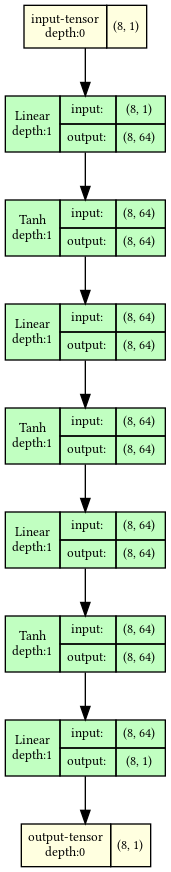

In [15]:
try:
    import os
    from torchview import draw_graph
    from IPython.display import Image
    graph = draw_graph(model, input_size=(8, 1), expand_nested=True)
    os.makedirs("figures", exist_ok=True)
    png = graph.visual_graph.render("figures/lab008_model_graph", format="png", cleanup=True)   # Graphviz writes the PNG file
    display(Image(png))
except Exception as err:
    print("torchview drawing not available:", err)

The tools are faster to use, and they are the right choice for large models. The `torchinfo` table is the quickest check of shapes and parameter counts;
the `torchview` graph shows how the layers are connected, which matters once the data flow is not a single chain (skip connections, several inputs). The direct computations of Sections 1.1–1.6 remain useful: they show what the numbers
mean, and they can be extended to any quantity a tool does not provide (e.g. the saturation of the activations in Section 2.3).

<hr/>
## 2. The network before training

### 2.1 Damped-oscillation data
The data are noisy measurements of a damped oscillation
$$y(t) = e^{-0.2t}\cos(2t), \qquad t\in[0, 10], \tag{7}$$
with noise of standard deviation $\sigma$, 0.1, and deliberately **few** training points, so that overfitting (Section 4) becomes visible: 30 points for training, 40 for validation, 40 for testing.
The input is rescaled to $[-1, 1]$.

The numbers are chosen for this purpose. The noise $0.1$ is about 10% of the amplitude of the signal, which starts at 1: large enough for overfitting to be
visible, small enough for the oscillation to remain recognisable. With only 30 training points the network of Section 1 (8513 parameters) can memorise the
training set. The validation and test sets are larger (40 points each) because their losses are used to choose and to evaluate the model, and a larger set
gives a less noisy estimate. The positions $t$ are drawn uniformly at random, so the three sets cover the interval in the same way; all 110
points are drawn at once, and the first 30, the next 40 and the last 40 form the three sets.

Besides the data, the cell creates `t_plot` (400 equally spaced values) and the corresponding network input `X_plot`. These are not data: they are a dense
grid on which functions are evaluated for plotting, and on which the hidden layers are examined in Section 2.3. The rescaling
$$t \;\to\; t/5 - 1 \tag{8}$$
maps $[0, 10]$ onto $[-1, 1]$. $\tanh$ changes only for arguments of order one; with the raw inputs (up to 10) and first-layer weights in $[-1, 1]$, 52% of the
first-layer activations of the untrained network would be saturated (Section 2.3), with the rescaled inputs below 0.1%.

training: (30, 1)  validation: (40, 1)  test: (40, 1)


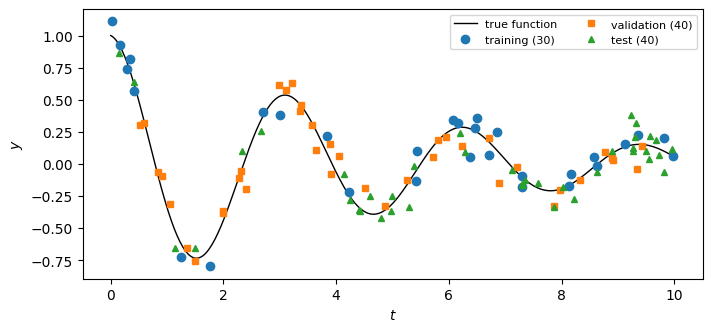

In [16]:
def damped_oscillation(t):
    return np.exp(-0.2 * t) * np.cos(2 * t)

noise = 0.1
rng = np.random.default_rng(0)
t_all = rng.uniform(0, 10, 110)
y_all = damped_oscillation(t_all) + noise * rng.normal(size=110)

def to_tensor(t, y):
    """Inputs rescaled to [-1, 1] and targets, both of shape (B, 1), float32."""
    X = torch.tensor(t / 5.0 - 1.0, dtype=torch.float32).reshape(-1, 1)
    Y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    return X, Y

X_train, Y_train = to_tensor(t_all[:30], y_all[:30])        # the points are in random order already
X_val, Y_val = to_tensor(t_all[30:70], y_all[30:70])
X_test, Y_test = to_tensor(t_all[70:], y_all[70:])
print("training:", tuple(X_train.shape), " validation:", tuple(X_val.shape), " test:", tuple(X_test.shape))

t_plot = np.linspace(0, 10, 400)
X_plot = torch.tensor(t_plot / 5.0 - 1.0, dtype=torch.float32).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function")
ax.plot(t_all[:30], y_all[:30], "o", label="training (30)")
ax.plot(t_all[30:70], y_all[30:70], "s", ms=4, label="validation (40)")
ax.plot(t_all[70:], y_all[70:], "^", ms=4, label="test (40)")
ax.set_xlabel("$t$"); ax.set_ylabel("$y$"); ax.legend(fontsize=8, ncol=2); plt.show()

### 2.2 Initial weights
PyTorch initialises the weights of `nn.Linear(n_in, n_out)` uniformly in $[-1/\sqrt{n_{\rm in}},\ 1/\sqrt{n_{\rm in}}]$. The first layer (one input) therefore
has weights in $[-1, 1]$, the hidden layers (64 inputs) in $[-0.125, 0.125]$. The histograms below show the weights of every `Linear` layer of the
untrained model, with these bounds as dashed lines. The biases are drawn from the same interval.

The scale $1/\sqrt{n_{\rm in}}$ keeps the size of the weighted sum
$$s = \sum_{i=1}^{n_{\rm in}} w_i x_i \tag{9}$$
independent of the number of inputs: for independent $w_i$ and $x_i$ with zero mean
$${\rm Var}(s) = n_{\rm in}\,{\rm Var}(w)\,{\rm Var}(x), \tag{10}$$
which does not grow with $n_{\rm in}$ when
$${\rm Var}(w)\propto 1/n_{\rm in} . \tag{11}$$

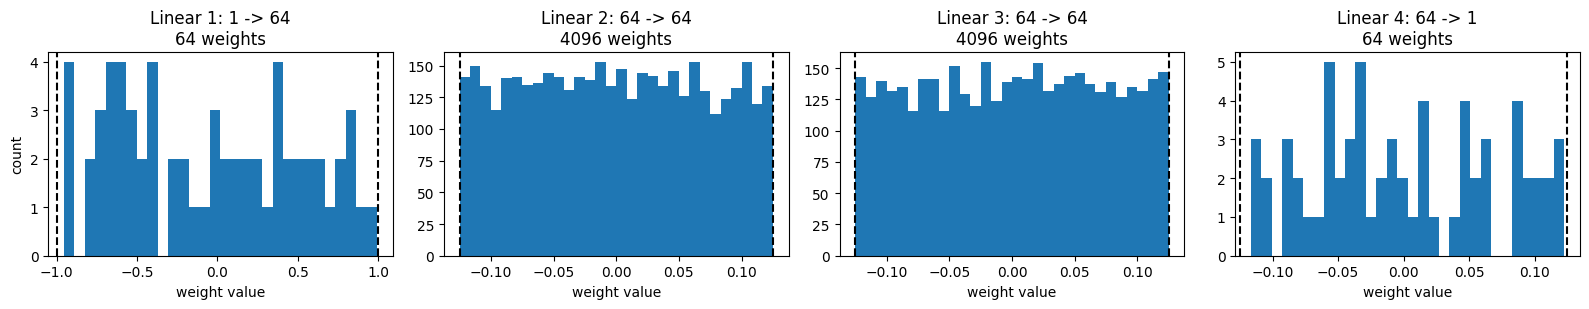

In [17]:
linear_layers = [layer for layer in model if isinstance(layer, nn.Linear)]
fig, axes = plt.subplots(1, len(linear_layers), figsize=(16, 3.2))
for k, (ax, layer) in enumerate(zip(axes, linear_layers)):
    w = layer.weight.detach().numpy().ravel()
    bound = 1 / np.sqrt(layer.in_features)
    ax.hist(w, bins=30)                                         # bins: enough to show the shape, a matter of readability
    ax.axvline(-bound, color="k", ls="--"); ax.axvline(bound, color="k", ls="--")
    ax.set_title(f"Linear {k + 1}: {layer.in_features} -> {layer.out_features}\n{w.size} weights")
    ax.set_xlabel("weight value")
axes[0].set_ylabel("count")
fig.tight_layout(); plt.show()

The weight histograms above are flat between the dashed bounds, as expected for a uniform distribution; the panels with only 64 weights are irregular
because 64 samples are few.

### 2.3 Activations and saturated nodes
The 400 inputs of the dense grid `X_plot` are passed through the network, and the output of every activation layer is recorded.
A node computes $\tanh$ of its weighted input $z$,
$$h = \tanh z, \qquad \frac{dh}{dz} = 1 - \tanh^2 z = 1 - h^2 . \tag{12}$$
A node is **saturated** when
$$|h| > 0.95, \qquad\text{so that}\qquad \frac{dh}{dz} = 1-h^2 < 0.0975 \approx 0.1 : \tag{13}$$
its derivative is small, so gradients passing through it are damped by a
factor of ten or more. The threshold 0.95 is a convention; any value between about 0.9 and 0.99 gives the same qualitative picture.
The *saturated fraction* of a layer, shown in the panel titles below, is the fraction of activation values $h$ (over all nodes and all 400 inputs) that satisfy the condition (13).

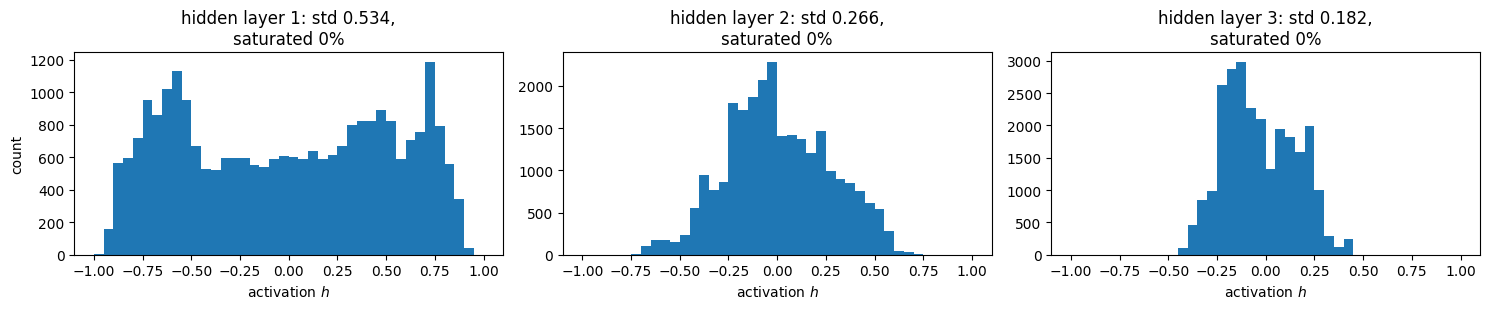

In [18]:
def hidden_activations(model, x):
    """Outputs of all activation layers of an nn.Sequential model for the input batch x."""
    outputs = []
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            if not isinstance(layer, nn.Linear):     # keep the outputs of the activation layers only
                outputs.append(x.numpy().copy())   # .numpy() shares memory with the tensor; copy() makes the stored array independent
    return outputs

acts = hidden_activations(model, X_plot)
fig, axes = plt.subplots(1, len(acts), figsize=(15, 3.2))
for k, (ax, h) in enumerate(zip(axes, acts)):
    saturated = np.mean(np.abs(h) > 0.95)
    ax.hist(h.ravel(), bins=40, range=(-1, 1))     # the full range of tanh, the same in every panel so that they can be compared
    ax.set_title(f"hidden layer {k + 1}: std {h.std():.3f},\nsaturated {100 * saturated:.0f}%")
    ax.set_xlabel("activation $h$")
axes[0].set_ylabel("count")
fig.tight_layout(); plt.show()

With the default initialisation practically no activation is saturated (below 0.1%), and the spread of the activations shrinks from layer to layer: the signal becomes weaker with depth.

### 2.4 Gradients in every layer
One forward and one backward pass on the training set give the gradient of the loss with respect to every weight matrix. Its norm tells how strongly each
layer would be changed by the first step of gradient descent.

`model.zero_grad()` first sets the stored gradients to zero, because PyTorch adds new gradients to those already in `.grad`.
`nn.functional.mse_loss(a, b)` is the function form of `nn.MSELoss()(a, b)` and gives the same value. For a matrix, `.norm()` is the Frobenius norm
$$\|g\| = \sqrt{\sum_{ij} g_{ij}^2} , \tag{14}$$
the length of the matrix viewed as one long vector.

In [19]:
def gradient_norms(model, X, Y):
    """Norm of dL/dW for the weight matrix of every Linear layer (one backward pass)."""
    model.zero_grad()
    nn.functional.mse_loss(model(X), Y).backward()
    return [layer.weight.grad.norm().item() for layer in model if isinstance(layer, nn.Linear)]

for k, g in enumerate(gradient_norms(model, X_train, Y_train)):
    print(f"Linear {k + 1}: |dL/dW| = {g:.2e}")

Linear 1: |dL/dW| = 1.41e-02
Linear 2: |dL/dW| = 4.85e-01
Linear 3: |dL/dW| = 5.12e-01
Linear 4: |dL/dW| = 7.12e-01


The gradient of the first layer is the smallest. Gradient norms of different layers are, however, not directly comparable: the first weight matrix has only
$64$ entries, the hidden ones 4096 (a $64\times64$ matrix), and the norm sums over all entries. Comparisons are meaningful for the same layer between different models
or different epochs, as in Sections 2.5 and 3.2.

### 2.5 The influence of the initialisation scale
The analysis of Sections 2.3–2.4 is repeated for a deeper network (6 hidden layers of width 64) whose weights are drawn from $\mathcal N(0, (c/\sqrt{n_{\rm in}})^2)$, the normal (Gaussian)
distribution with mean 0 and standard deviation $c/\sqrt{n_{\rm in}}$, for three values of $c$. The table lists, for every hidden layer, the standard deviation of the activations and the fraction of saturated nodes, and the gradient
norm of every weight matrix.

The three values stand for a too small, a standard and a too large scale. Their effect is multiplied once per layer, so a network deeper than that of
Section 1 makes it easier to see. A normal distribution is used instead of PyTorch's uniform one, because only the standard deviation matters for the
argument. For comparison, the default uniform distribution on $[-1/\sqrt{n_{\rm in}}, 1/\sqrt{n_{\rm in}}]$ has standard deviation $1/\sqrt{3n_{\rm in}}$,
which corresponds to
$$c = 1/\sqrt3 \approx 0.58 ; \tag{15}$$
this is why the activations of Section 2.3 shrink with depth.

In the code, the functions of `nn.init` overwrite the values of an existing tensor in place (in PyTorch a trailing underscore, as in `normal_`, marks an
in-place operation), and the biases are set to zero so that only the weight scale is varied. The activations are measured on the dense grid `X_plot`, which
samples the input interval evenly; the gradients are those of the training loss and need the training data. Finally, `pivot` rearranges the long table
(one row per pair ($c$, layer)) into a wide one with one row per layer and one column per quantity and value of $c$, so that the three values of $c$ stand
side by side; `round(4)` only affects the display.

In [20]:
def init_scaled(layer_sizes, c, seed=0):
    torch.manual_seed(seed)
    m = make_mlp(layer_sizes)
    for layer in m:
        if isinstance(layer, nn.Linear):
            nn.init.normal_(layer.weight, mean=0.0, std=c / np.sqrt(layer.in_features))
            nn.init.zeros_(layer.bias)
    return m

deep_sizes = [1] + [64] * 6 + [1]
rows = []
for c in [0.5, 1.0, 3.0]:
    m = init_scaled(deep_sizes, c)
    acts = hidden_activations(m, X_plot)
    grads = gradient_norms(m, X_train, Y_train)
    for k, h in enumerate(acts):
        rows.append({"c": c, "hidden layer": k + 1, "activation std": h.std(),
                     "saturated (%)": 100 * np.mean(np.abs(h) > 0.95), "|dL/dW| of this layer": grads[k]})
init_table = pd.DataFrame(rows)
init_table.pivot(index="hidden layer", columns="c", values=["activation std", "saturated (%)", "|dL/dW| of this layer"]).round(4)

activation std                 saturated (%)                   \
c                       0.5     1.0     3.0           0.5     1.0      3.0   
hidden layer                                                                 
1                    0.2449  0.4103  0.6834           0.0  0.3906  21.3359   
2                    0.1226  0.3478  0.7538           0.0  0.0000  33.4844   
3                    0.0649  0.3224  0.7928           0.0  0.0000  43.4531   
4                    0.0349  0.3061  0.8262           0.0  0.0000  47.6094   
5                    0.0165  0.2689  0.8368           0.0  0.0000  46.3984   
6                    0.0072  0.2261  0.8138           0.0  0.0000  40.9922   

             |dL/dW| of this layer                   
c                              0.5     1.0      3.0  
hidden layer                                         
1                           0.0023  0.0651   5.5637  
2                           0.0158  0.4404  33.0961  
3                           0.0163  0.4131  28.2800  
4                           0.0178  0.4165  18.5721  
5                           0.0204  0.4521  13.6979  
6                           0.0195  0.4305  12.9121

For the smallest scale, $c$ of 0.5, the activations shrink by about a factor of two per layer, and all gradients are more than twenty times smaller than for
the standard scale 1, decreasing slightly towards the first layers: the signal fades in both directions (**vanishing gradients**). For the standard scale
the activations decrease with depth only slowly (for $\tanh$ the derivative is below 1, so this scale does not exactly preserve the signal), and the gradients
are of similar size in hidden layers 2–6 (layer 1 has only 64 weights, so its norm is smaller; see Section 2.4). For the largest scale, 3, a large fraction
of the nodes (up to about half in the deeper layers) is saturated, and the gradients are tens of times larger than for the standard scale: the first optimisation steps would be very large (**exploding gradients**).

The weight scale therefore has to be chosen with the depth and the activation in mind; standard choices are derived from such arguments.
Xavier (Glorot) initialisation uses
$${\rm Var}(w) = \frac{2}{n_{\rm in}+n_{\rm out}} , \tag{16}$$
a scale $c$ of 1 for square layers, and is meant for $\tanh$-like activations. He initialisation uses
$${\rm Var}(w) = \frac{2}{n_{\rm in}} , \tag{17}$$
a scale $c$ of $\sqrt2$, which compensates for the rectified linear unit (ReLU),
$$\mathrm{ReLU}(z)=\max(0,z) , \tag{18}$$
which sets negative inputs (about half of them) to zero.

<hr/>
## 3. Monitoring training

The training function below is a standard training loop (full batch, Adam) with additional bookkeeping. After every epoch it records the training loss and
the validation loss, the norm of the gradient of every weight matrix, and the relative change of every weight matrix since the start,
$\|W(e) - W(0)\| / \|W(0)\|$, where $e$ is the epoch. It also keeps a copy of the parameters at the epoch with the smallest validation loss so far, which
Section 4 uses.

The record `log` is a dictionary of lists, with one entry appended per epoch. For the gradients and weight
changes each entry is a list of 4 numbers (one per `Linear` layer); at the end `np.array` turns this list of lists into an array of shape (number of epochs, 4),
so that `log["grad"][:, k]` is the history of layer $k+1$. The 30 training points form one batch, so every epoch is a single exact gradient step and the loss
curves contain no noise from a random choice of mini-batches.

The learning rate `lr=1e-2` is a common starting value for Adam on small problems; it was not tuned. With learning rates $10^{-3}$,
$3\cdot10^{-3}$, $10^{-2}$ and $3\cdot10^{-2}$ the smallest validation loss is reached at epochs 753, 419, 293 and 281, and in every case the validation
loss rises afterwards. The 3000 epochs are far more than needed to reach the minimum, so that the overfitting after it can be seen.

Three copies in the code protect stored values from later changes. In `W0 = [... .detach().clone() ...]` the `clone()` is needed because `optimizer.step()`
changes the weights in place: without it the list would hold the current weight tensors themselves and the relative change would always be zero, while
`detach()` keeps the copy out of the gradient computation. The record `best = {"val": np.inf, ...}` starts from infinity, so the validation loss of the first
epoch is always smaller and becomes the first "best" model. Its parameters are stored with `copy.deepcopy(model.state_dict())`, because `state_dict()`
returns a dictionary of the parameter tensors themselves, not of copies; without `deepcopy` the stored "best" state would follow every later optimiser step
and end up equal to the final parameters.

`model.train()` and `model.eval()` switch layers such as dropout and batch normalisation between their training and evaluation behaviour. This network has
no such layers, so here the calls change nothing; they are kept because a general training loop needs them. The training loss of an epoch is computed before
`optimizer.step()`, the validation loss after it; the two curves are shifted by one step, which is irrelevant on a scale of thousands of epochs. Finally,
`torch.manual_seed(0)` before `make_mlp` gives the same initial weights as in Sections 1–2: the model trained here is exactly the one analysed above.

In [21]:
def train_monitored(model, n_epochs=3000, lr=1e-2):
    linear = [layer for layer in model if isinstance(layer, nn.Linear)]
    W0 = [layer.weight.detach().clone() for layer in linear]          # initial weights, for the relative change
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    log = {"train": [], "val": [], "grad": [], "change": []}
    best = {"val": np.inf, "epoch": None, "state": None}
    for epoch in range(n_epochs):
        model.train()
        loss = loss_fn(model(X_train), Y_train)
        optimizer.zero_grad()
        loss.backward()
        log["grad"].append([layer.weight.grad.norm().item() for layer in linear])    # read the gradients before the step
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), Y_val).item()
            log["change"].append([((layer.weight - w0).norm() / w0.norm()).item() for layer, w0 in zip(linear, W0)])
        log["train"].append(loss.item())
        log["val"].append(val_loss)
        if val_loss < best["val"]:                                     # remember the best model so far
            best = {"val": val_loss, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    log["grad"], log["change"] = np.array(log["grad"]), np.array(log["change"])
    return log, best

torch.manual_seed(0)
model = make_mlp(layer_sizes)
t0 = time.perf_counter()
log, best = train_monitored(model)
train_time = time.perf_counter() - t0
print(f"training took {train_time:.1f} s;  smallest validation loss {best['val']:.3e} at epoch {best['epoch']}")

training took 5.0 s;  smallest validation loss 1.941e-02 at epoch 293


### 3.1 Learning curves
The losses on the training and validation sets against the epoch are the most important plot of every training run. The dotted line is the noise variance
$\sigma^2$, 0.01, the smallest mean squared error (MSE) that any model can reach on new data; the vertical line marks the epoch with the smallest validation loss.

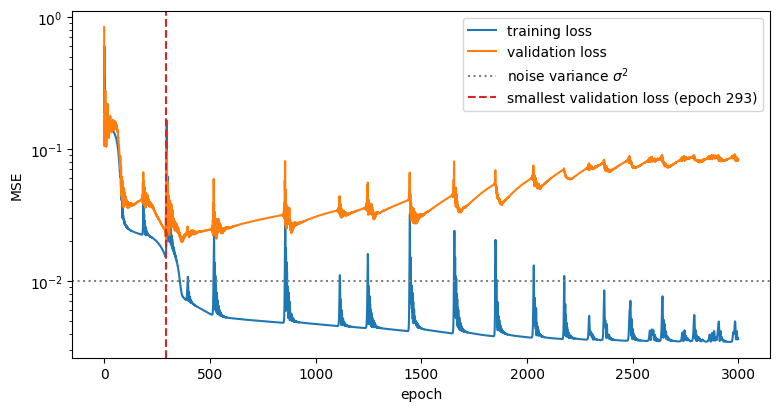

at the end: training loss 3.65e-03, validation loss 8.35e-02


In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(log["train"], label="training loss")
ax.semilogy(log["val"], label="validation loss")
ax.axhline(noise**2, color="gray", ls=":", label=r"noise variance $\sigma^2$")
ax.axvline(best["epoch"], color="C3", ls="--", label=f"smallest validation loss (epoch {best['epoch']})")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
plt.show()
print(f"at the end: training loss {log['train'][-1]:.2e}, validation loss {log['val'][-1]:.2e}")

Two phases are visible. At first both losses decrease together: the network learns the function that the training and validation points have in common.
Later the training loss keeps decreasing, **below the noise variance**, while the validation loss increases. Below $\sigma^2$ the network can only improve on
the training set by reproducing its particular noise, which is useless (in fact harmful) for new points. This is **overfitting**.
With 30 points even the true function has a training MSE that fluctuates around $\sigma^2$ by about
$$\sigma^2\sqrt{2/30} \approx 0.25\,\sigma^2 , \tag{19}$$
so only a training loss
well below $\sigma^2$, as here at the end of training, is a clear sign of fitting the noise.

### 3.2 Gradients and weight changes per layer
The same run can be followed inside the network. The gradient norms vary over several orders of magnitude and are plotted on a logarithmic axis; the
relative weight changes stay between 0 and about 3 and are readable on a linear axis.

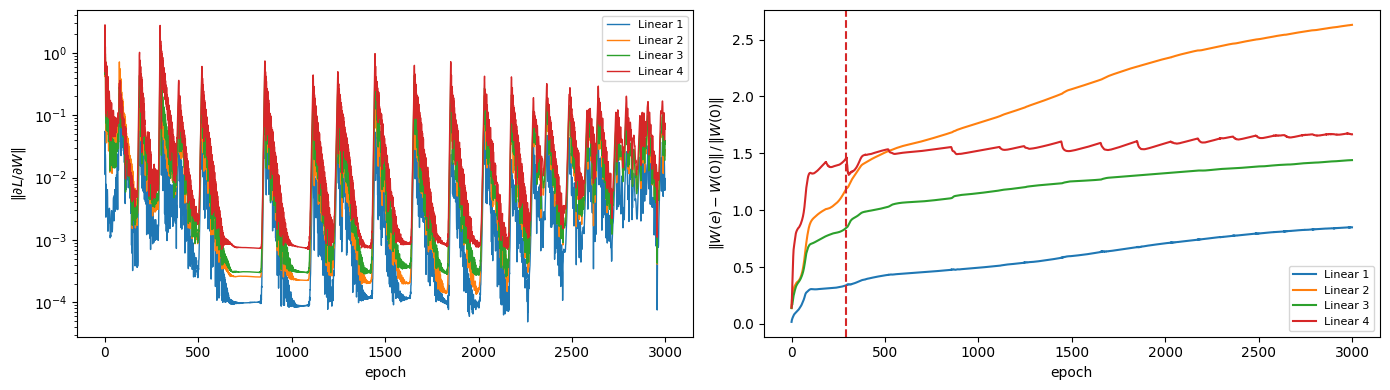

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for k in range(log["grad"].shape[1]):
    axes[0].semilogy(log["grad"][:, k], lw=1, label=f"Linear {k + 1}")
    axes[1].plot(log["change"][:, k], label=f"Linear {k + 1}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel(r"$\|\partial L/\partial W\|$"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel(r"$\|W(e) - W(0)\|\,/\,\|W(0)\|$"); axes[1].legend(fontsize=8)
axes[1].axvline(best["epoch"], color="C3", ls="--")
fig.tight_layout(); plt.show()

The gradient norms decay during long stretches, interrupted by sudden spikes: at a spike the Adam step overshoots, the loss jumps up for a few epochs and then
decreases again. These episodes are also visible as small jumps in the right panel, which shows how far each weight matrix has moved from its initial
values. Relative changes of order one mean that training has substantially rewritten the layer; changes that keep growing after the best epoch (dashed
line) are the parameters adapting to the noise of the training set.
<hr/>
## 4. Overfitting and the choice of the epoch

`train_monitored` kept a copy of the parameters from the epoch with the smallest validation loss. Loading it gives the model that would have been obtained by
stopping the training there (**early stopping**). Both models are compared with the data.

A `state_dict` contains only numbers, not the architecture. A network with the same layer sizes is therefore built first, and its random initial parameters
are then overwritten by `load_state_dict`. `final_model = model` is not a copy, only a second name for the trained network.

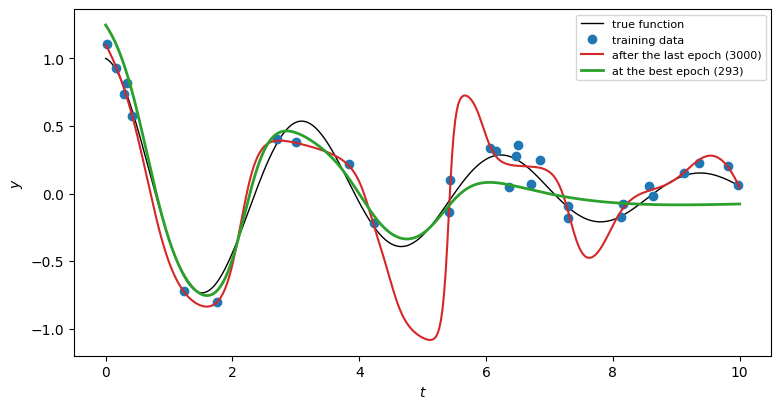

In [24]:
final_model = model                                   # parameters after the last epoch
best_model = make_mlp(layer_sizes)
best_model.load_state_dict(best["state"])             # parameters from the epoch with the smallest validation loss

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function")
ax.plot(t_all[:30], y_all[:30], "o", color="C0", label="training data")
with torch.no_grad():
    ax.plot(t_plot, final_model(X_plot), "C3", lw=1.5, label=f"after the last epoch ({len(log['train'])})")
    ax.plot(t_plot, best_model(X_plot), "C2", lw=2, label=f"at the best epoch ({best['epoch']})")
ax.set_xlabel("$t$"); ax.set_ylabel("$y$"); ax.legend(fontsize=8); plt.show()

The model after the last epoch passes close to the training points and makes large excursions in the gaps between them (e.g. around the time 5).
The model from the best epoch is smooth and follows the true function over most of the interval, but it misses the small oscillations at times above about 6.
The best epoch was chosen with the **validation** set: the test set has not been used yet.
<hr/>
## 5. Evaluation on the test set

Now, and only now, the chosen model is evaluated on the test set. Its test loss is the estimate of the error on new data that would be reported.
For illustration only, the test loss of the overfitted final model is printed as well; it was not used to make any choice. The three panels then show the
predictions against the measured values, the histogram of the residuals, and the residuals against the input $t$.

chosen model (best epoch 293): test MSE = 3.197e-02
final model (for comparison only)   : test MSE = 7.065e-02
noise variance                       : 1.000e-02
residuals: mean -0.027, standard deviation 0.177 (noise level sigma = 0.1)


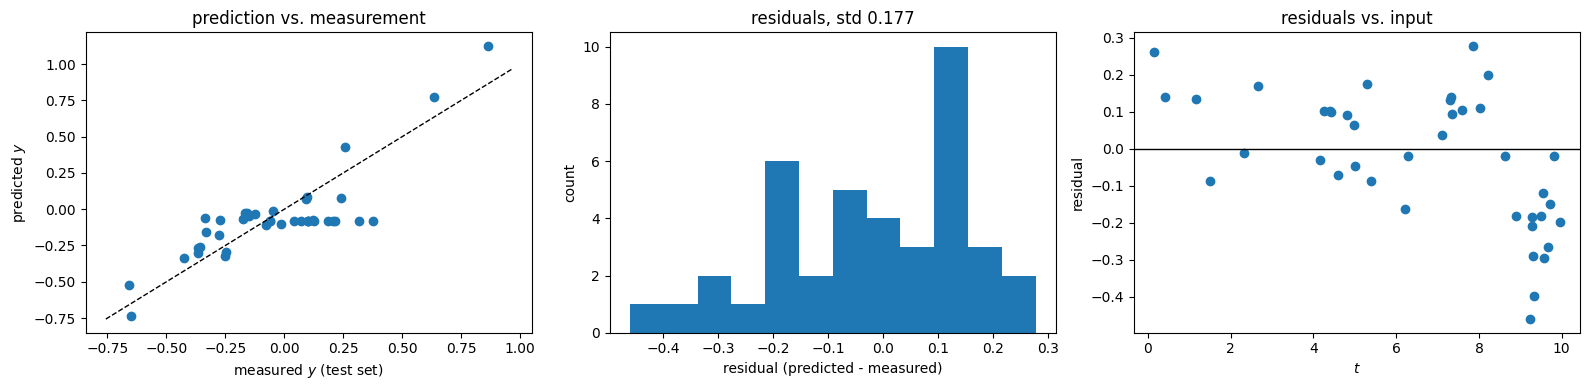

In [25]:
loss_fn = nn.MSELoss()
best_model.eval(); final_model.eval()
with torch.no_grad():
    test_best = loss_fn(best_model(X_test), Y_test).item()
    test_final = loss_fn(final_model(X_test), Y_test).item()
    pred_test = best_model(X_test).numpy().ravel()
print(f"chosen model (best epoch {best['epoch']}): test MSE = {test_best:.3e}")
print(f"final model (for comparison only)   : test MSE = {test_final:.3e}")
print(f"noise variance                       : {noise**2:.3e}")

residuals = pred_test - Y_test.numpy().ravel()
print(f"residuals: mean {residuals.mean():+.3f}, standard deviation {residuals.std():.3f} (noise level sigma = {noise})")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(Y_test.numpy(), pred_test, "o")
lims = [Y_test.min().item() - 0.1, Y_test.max().item() + 0.1]      # the margin 0.1 only extends the diagonal beyond the data
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("measured $y$ (test set)"); axes[0].set_ylabel("predicted $y$"); axes[0].set_title("prediction vs. measurement")
axes[1].hist(residuals, bins=12)                                  # few bins: only 40 residuals
axes[1].set_xlabel("residual (predicted - measured)"); axes[1].set_ylabel("count"); axes[1].set_title(f"residuals, std {residuals.std():.3f}")
axes[2].plot(t_all[70:], residuals, "o"); axes[2].axhline(0, color="k", lw=1)
axes[2].set_xlabel("$t$"); axes[2].set_ylabel("residual"); axes[2].set_title("residuals vs. input")
fig.tight_layout(); plt.show()

For an ideal model the points of the left panel lie around the diagonal, the residuals have a standard deviation equal to the noise level $\sigma$, 0.1, and
they show no trend with the input $t$. For $n$ Gaussian values the sample standard deviation scatters by about $\sigma/\sqrt{2n}$, so even for an ideal model
the standard deviation of the 40 residuals fluctuates around $0.1$ by about
$$\frac{\sigma}{\sqrt{2\cdot 40}} \approx 0.011 . \tag{20}$$

`residuals.std()` subtracts the mean residual, so a constant offset of the model does not enter it, while $\sqrt{\text{test MSE}}$ includes it.
Here the residual standard deviation (in the title of the middle panel) is larger than $\sigma$ by much more than this fluctuation, and the right panel shows
why: at times above about 9 all residuals are negative, i.e. the model is systematically too low in this region (it misses the last oscillation, see Section 4),
and between the times 7 and 8.3 all residuals are positive (the minimum of $y$ near the time 7.9 is too shallow in the model).
In the left panel the points at times above 9 form a horizontal row: the model predicts almost the same value, about $-0.08$, for all of them, whatever
the measured value. Residual plots reveal such systematic errors, which a single number
such as the test MSE hides.
<hr/>
## 6. Model characteristics table

The quantities of this notebook are collected for two models trained on the same data: the network analysed so far and a small network with one hidden layer of
16 nodes. Both are evaluated at their best epoch. The small network, with
$$16\cdot 2 + 17 = 49 \tag{21}$$
parameters, serves as a contrast: with one narrow hidden layer it
can represent only smooth functions, so it overfits much more slowly; its smallest validation loss is reached only at epoch 2880, near the end of the
3000 epochs, and at that epoch its training loss, $7.8\cdot10^{-3}$, is only slightly below $\sigma^2$. (With 30 points the training MSE of even the true
function fluctuates by about 25% around $\sigma^2$, equation (19).) Its width 16 is arbitrary.

`DataFrame.style.format` changes only how the numbers are displayed, not the stored values: `"{:.2f}"` means two decimal places, `"{:.2e}"` scientific notation
with two decimals. The training time depends on the computer and on other running processes; it is useful only to compare models trained on the same machine.

In [26]:
def characterise(sizes, seed=0):
    torch.manual_seed(seed)
    m = make_mlp(sizes)
    t0 = time.perf_counter()
    lg, bst = train_monitored(m)
    elapsed = time.perf_counter() - t0
    m.load_state_dict(bst["state"]); m.eval()
    with torch.no_grad():
        tr = loss_fn(m(X_train), Y_train).item()
        te = loss_fn(m(X_test), Y_test).item()
    return {
        "layer sizes": str(sizes),
        "parameters": sum(p.numel() for p in m.parameters()),
        "memory (kB)": sum(p.numel() * p.element_size() for p in m.parameters()) / 1024,
        "best epoch": bst["epoch"],
        "train MSE": tr, "val MSE": bst["val"], "test MSE": te,
        "train time (s)": elapsed,
    }

summary_table = pd.DataFrame([characterise([1, 16, 1]), characterise(layer_sizes)])
summary_table.style.format({"memory (kB)": "{:.2f}", "train MSE": "{:.2e}", "val MSE": "{:.2e}", "test MSE": "{:.2e}", "train time (s)": "{:.1f}"})

,layer sizes,parameters,memory (kB),best epoch,train MSE,val MSE,test MSE,train time (s)
0,"[1, 16, 1]",49,0.19,2880,7.80e-03,1.49e-02,1.43e-02,2.4
1,"[1, 64, 64, 64, 1]",8513,33.25,293,2.83e-02,1.94e-02,3.20e-02,4.9


With these 30 training points the small network has the smaller validation and test errors (test MSE about 0.014 against 0.032).
Here, with few data, more parameters do not give a better model. The large network reaches its best validation loss early (epoch 293), when its
training error is still above the noise variance; later it improves only on the training set. The small network has a lower training error at its best
epoch, because that epoch comes much later.

Such a table is the minimum documentation of a trained model: architecture and size, how it was selected (best epoch by validation loss), and its errors on the
three data sets. Only the test column is an unbiased estimate of the error on new data.
<hr/>
## 7. Summary
The architecture alone already gives a layer table (shapes and parameters per layer), the total and trainable numbers of parameters (`requires_grad`), the
memory ($4$ bytes per `float32` parameter) and the multiply-adds per sample; the number of parameters grows linearly with depth and quadratically with
width. Before training, the weight and activation histograms, the fraction of saturated nodes and the gradient norms per layer show whether the
initialisation scale lets signals and gradients shrink, survive or saturate with depth. During training, the training and validation losses against the
epoch, together with the gradient norms and relative weight changes per layer, show how the parameters evolve. Overfitting appears as a training loss
falling below the noise level while the validation loss rises; the parameters at the epoch with the smallest validation loss are kept (early stopping).
The test set is used once, for the chosen model, and residual plots show whether its errors are random or systematic.
<hr/>
## 8. Exercises

### Exercise 1 — Analysing an image classifier
The image classifier `nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))`
assigns a $28\times28$ grey-scale image of a handwritten digit (the MNIST data set, Modified National Institute of Standards and Technology database; Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, *Gradient-based learning applied to document recognition*, Proc. IEEE **86**, 2278–2324 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)) to one
of 10 **classes**, the digits $0, \dots, 9$: it has $784$ inputs, one per pixel, and 10 outputs, one per class.
1. Load the MNIST test images (`torchvision.datasets.MNIST`, `train=False`) and show one example of every class with its label.
2. Draw the network and produce its layer table with `layer_table` for a batch of 16 test images (pixel values divided by 255).
3. Which layer holds most of the parameters, and what fraction? Why is it this layer?
4. Compute the memory of the parameters and the number of multiply-adds per image.
5. Freeze everything except the last layer and report the number of trainable parameters. Check the totals with `torchinfo.summary` (Section 1.7).

#### Solution

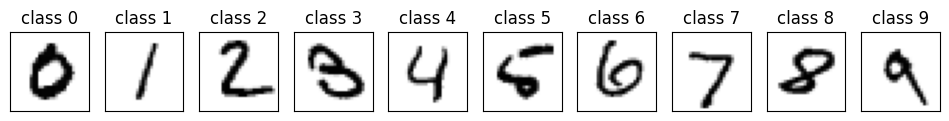

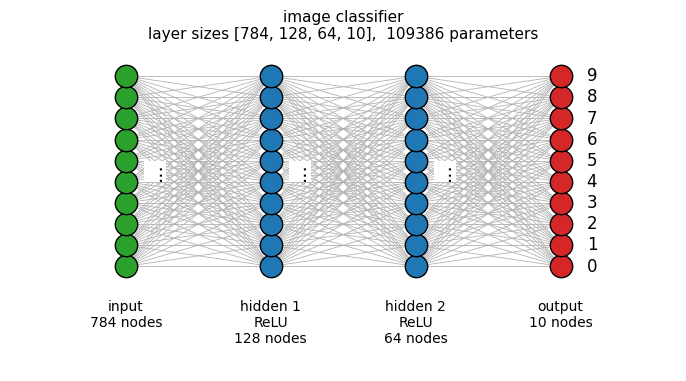

 index   layer  input shape output shape     parameter shapes  parameters  trainable
     0 Flatten (16, 28, 28)    (16, 784)                   []           0          0
     1  Linear    (16, 784)    (16, 128) [(128, 784), (128,)]      100480     100480
     2    ReLU    (16, 128)    (16, 128)                   []           0          0
     3  Linear    (16, 128)     (16, 64)   [(64, 128), (64,)]        8256       8256
     4    ReLU     (16, 64)     (16, 64)                   []           0          0
     5  Linear     (16, 64)     (16, 10)    [(10, 64), (10,)]         650        650

largest layer: index 1 (Linear) with 100480 of 109386 parameters = 91.9%
memory: 427 kB,  multiply-adds per image: 109184
trainable parameters after freezing: 650 (= 64 x 10 + 10)
torchinfo: total 109386  trainable 650


In [27]:
import contextlib, io

# 1) data: the MNIST test set (random numbers if the download fails)
try:
    from torchvision import datasets
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mnist = datasets.MNIST(root="data", train=False, download=True)
    images_raw, labels = mnist.data, mnist.targets
except Exception as err:
    print("MNIST could not be loaded:", err)
    images_raw = torch.randint(0, 256, (10000, 28, 28), dtype=torch.uint8)
    labels = torch.randint(0, 10, (10000,))
images = images_raw.float() / 255                    # pixel values in [0, 1]

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for k, ax in enumerate(axes):
    first = torch.nonzero(labels == k)[0, 0]          # position of the first image of class k
    ax.imshow(images_raw[first], cmap="gray_r")
    ax.set_title(f"class {k}"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

clf = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

# 2) drawing and table
assert dense_parameter_count(linear_sizes(clf)) == sum(p.numel() for p in clf.parameters())
draw_network(linear_sizes(clf), activations=["ReLU", "ReLU"], title="image classifier",
             output_labels=[f"{k}" for k in range(10)])
plt.show()
clf_table = layer_table(clf, images[:16])            # 16 test images, shape (16, 28, 28)
print(clf_table.to_string(index=False))              # print the whole table without the row-number column

# 3) share of the largest layer
total = clf_table["parameters"].sum()
largest = clf_table.loc[clf_table["parameters"].idxmax()]   # idxmax(): row label of the largest value; .loc[label]: that row
print(f"\nlargest layer: index {largest['index']} ({largest['layer']}) with {largest['parameters']} of {total} parameters "
      f"= {100 * largest['parameters'] / total:.1f}%")
# It is the first Linear layer: every one of its 128 nodes has one weight per pixel, 784 x 128 weights in total.

# 4) memory and multiply-adds
n_bytes = sum(p.numel() * p.element_size() for p in clf.parameters())
mult_adds = sum(l.in_features * l.out_features for l in clf if isinstance(l, nn.Linear))
print(f"memory: {n_bytes / 1024:.0f} kB,  multiply-adds per image: {mult_adds}")

# 5) freeze all parameters, then unfreeze the last layer
for p in clf.parameters():
    p.requires_grad = False
for p in clf[-1].parameters():
    p.requires_grad = True
print("trainable parameters after freezing:", sum(p.numel() for p in clf.parameters() if p.requires_grad), "(= 64 x 10 + 10)")
info = torchinfo.summary(clf, input_size=(16, 28, 28), verbose=0)
print("torchinfo: total", info.total_params, " trainable", info.trainable_params)

### Exercise 2 — Early stopping with patience
In practice training is stopped automatically once the validation loss has not improved for a number of epochs (the *patience*).
Modify the training loop so that it stops after 200 epochs without a new minimum of the validation loss, restore the best parameters, and report
the stopping epoch, the best epoch, the time saved compared with 3000 epochs, and the test loss of the restored model.

The patience must be longer than the temporary rises of the validation loss (the spikes of Section 3.2), otherwise training stops at one of them. With the
network and data of this notebook a patience of 100 epochs stops at epoch 213 with the best epoch 113 and validation loss 0.036, nearly twice the minimum
found in Section 3; patience 200 and 500 both find the minimum at epoch 293.

#### Solution

stopped at epoch 493, best epoch 293, 0.9 s instead of about 5.0 s for 3000 epochs
test MSE of the restored model: 3.197e-02


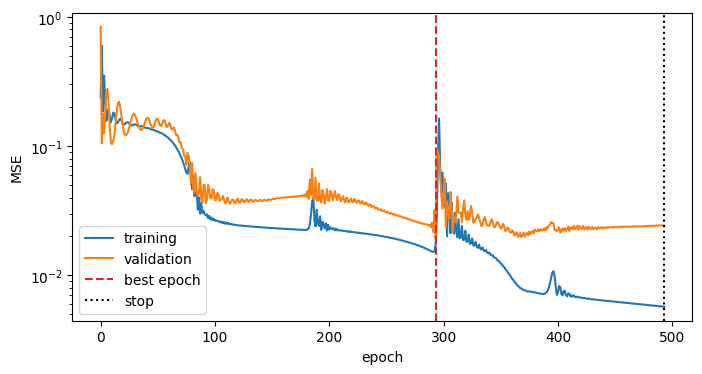

In [28]:
def train_early_stopping(model, max_epochs=3000, patience=200, lr=1e-2):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_epoch, best_state = np.inf, 0, None
    train_hist, val_hist = [], []
    for epoch in range(max_epochs):
        model.train()
        loss = loss_fn(model(X_train), Y_train)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_val), Y_val).item()
        train_hist.append(loss.item()); val_hist.append(val)
        if val < best_val:
            best_val, best_epoch, best_state = val, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:          # no improvement for `patience` epochs
            break                                     # leave the loop; `epoch` keeps its last value
    model.load_state_dict(best_state)                 # restore the best parameters
    return epoch, best_epoch, train_hist, val_hist

torch.manual_seed(0)
m = make_mlp(layer_sizes)
t0 = time.perf_counter()
stop_epoch, best_epoch, tr_h, va_h = train_early_stopping(m)
elapsed = time.perf_counter() - t0
with torch.no_grad():
    test_mse = loss_fn(m(X_test), Y_test).item()
print(f"stopped at epoch {stop_epoch}, best epoch {best_epoch}, {elapsed:.1f} s instead of about {train_time:.1f} s for 3000 epochs")
print(f"test MSE of the restored model: {test_mse:.3e}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(tr_h, label="training"); ax.semilogy(va_h, label="validation")
ax.axvline(best_epoch, color="C3", ls="--", label="best epoch"); ax.axvline(stop_epoch, color="k", ls=":", label="stop")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(); plt.show()

### Exercise 3 — More training data
Repeat the training of Section 3 (same network, same validation set) with 30, 100 and 300 training points (generate the additional points with
the same function and noise). Plot the training and validation loss versus epoch for the three cases in one figure (same colour per case, solid = training,
dashed = validation). How does the gap between training and validation loss change with the amount of data?

#### Solution

 30 training points: final training MSE 3.65e-03, final validation MSE 8.35e-02, smallest validation MSE 1.94e-02


100 training points: final training MSE 6.76e-03, final validation MSE 1.85e-02, smallest validation MSE 1.34e-02


300 training points: final training MSE 9.40e-03, final validation MSE 9.82e-03, smallest validation MSE 9.41e-03


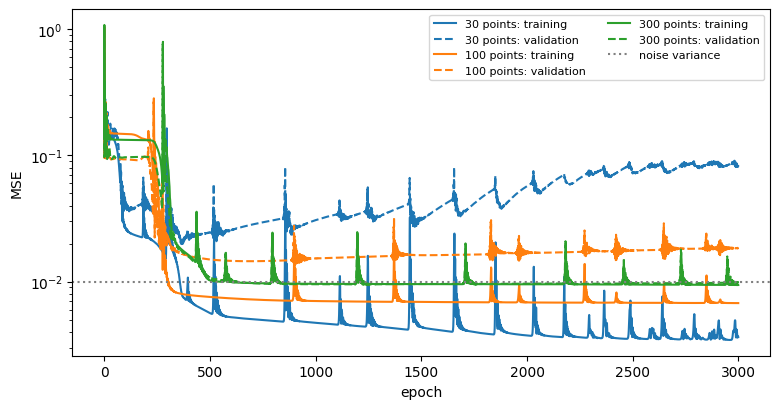

In [29]:
rng_extra = np.random.default_rng(10)                         # a different seed: new, independent points
t_extra = rng_extra.uniform(0, 10, 270)
y_extra = damped_oscillation(t_extra) + noise * rng_extra.normal(size=270)
X_val_fixed, Y_val_fixed = X_val, Y_val                       # only new names: the validation set is the same in all three runs

fig, ax = plt.subplots(figsize=(9, 4.5))
for color, n in zip(["C0", "C1", "C2"], [30, 100, 300]):
    t_n = np.concatenate([t_all[:30], t_extra[:n - 30]])        # the original 30 points plus new ones (np.concatenate joins arrays end to end)
    y_n = np.concatenate([y_all[:30], y_extra[:n - 30]])
    Xn, Yn = to_tensor(t_n, y_n)
    torch.manual_seed(0)
    m = make_mlp(layer_sizes)
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    tr_h, va_h = [], []
    for epoch in range(3000):
        loss = loss_fn(m(Xn), Yn)
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            va_h.append(loss_fn(m(X_val_fixed), Y_val_fixed).item())
        tr_h.append(loss.item())
    ax.semilogy(tr_h, color=color, label=f"{n} points: training")
    ax.semilogy(va_h, color=color, ls="--", label=f"{n} points: validation")
    print(f"{n:3d} training points: final training MSE {tr_h[-1]:.2e}, final validation MSE {va_h[-1]:.2e}, smallest validation MSE {min(va_h):.2e}")
ax.axhline(noise**2, color="gray", ls=":", label="noise variance")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(fontsize=8, ncol=2); plt.show()
# With more data the network cannot reproduce the noise of every training point any more: the training loss stays
# closer to the noise variance, the validation loss rises less, and the gap between the two shrinks.

### Exercise 4 — Training only the last layer
Freeze all layers of a fresh `make_mlp(layer_sizes)` except the last `Linear` layer and train it as in Section 3. The network is then a linear combination of
64 fixed random functions (the outputs of the last hidden layer) plus a constant (the bias): 65 trainable parameters. Compare the number of trainable parameters, the smallest validation loss and the fit with
the fully trained network. Plot the 64 fixed functions.

#### Solution

trainable parameters: 65 of 8513


smallest validation MSE: last layer only 9.40e-02,  full training 1.94e-02


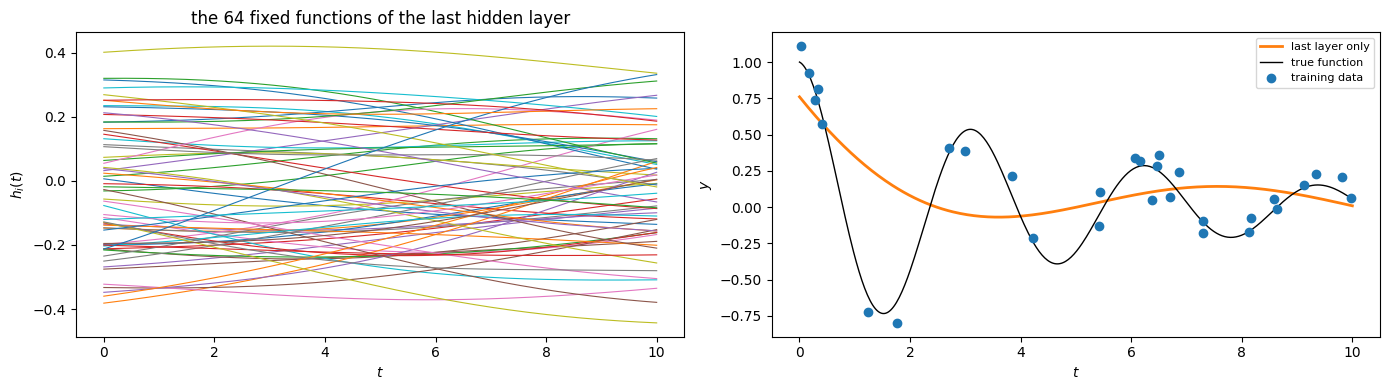

In [30]:
torch.manual_seed(0)
m_last = make_mlp(layer_sizes)
for p in m_last.parameters():
    p.requires_grad = False
for p in m_last[-1].parameters():                       # the last Linear layer stays trainable
    p.requires_grad = True
print("trainable parameters:", sum(p.numel() for p in m_last.parameters() if p.requires_grad),
      "of", sum(p.numel() for p in m_last.parameters()))

# only trainable parameters are given to the optimiser
opt = torch.optim.Adam([p for p in m_last.parameters() if p.requires_grad], lr=1e-2)
va_h = []
for epoch in range(3000):
    loss = loss_fn(m_last(X_train), Y_train)
    opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        va_h.append(loss_fn(m_last(X_val), Y_val).item())
print(f"smallest validation MSE: last layer only {min(va_h):.2e},  full training {best['val']:.2e}")

features = hidden_activations(m_last, X_plot)[-1]      # (400, 64): the fixed functions of the last hidden layer
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_plot, features, lw=0.8)
axes[0].set_xlabel("$t$"); axes[0].set_ylabel("$h_i(t)$"); axes[0].set_title("the 64 fixed functions of the last hidden layer")
with torch.no_grad():
    axes[1].plot(t_plot, m_last(X_plot), "C1", lw=2, label="last layer only")
axes[1].plot(t_plot, damped_oscillation(t_plot), "k", lw=1, label="true function")
axes[1].plot(t_all[:30], y_all[:30], "o", label="training data")
axes[1].set_xlabel("$t$"); axes[1].set_ylabel("$y$"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
# The fixed functions of a randomly initialised network are smooth and vary slowly (Section 2.3: the signal shrinks
# with depth), so a linear combination of them cannot follow the oscillation: the hidden layers must be trained too.